# 02 · Diferencias en diferencias y control sintético

> Datos **simulados**, fraude **plantado** sobre líneas y empresas ficticias. Ver `00c_simulacion_secciones.ipynb`.
> Con datos reales, esto produciría "anomalías a revisar", nunca prueba de fraude.

El método 01 responde *¿cambió la serie?* Este método responde algo más útil para una causa judicial: **¿cuánto cambió respecto de lo que habría pasado sin el cambio?**
Y de ahí, **¿cuánto es el perjuicio?** Para eso hace falta un *contrafactual*: la tarifa media que esa línea habría tenido si no hubiera pasado nada.

## Idea intuitiva 1 · Diferencias en diferencias (DiD)
Tomás un grupo de líneas sospechadas y otro de líneas "normales". Mirás cuánto cambió la tarifa media en cada grupo antes y después de una fecha.
Si las normales no cambiaron y las sospechadas subieron, la diferencia entre ambos cambios es el efecto atribuible. Restar el cambio del grupo normal descuenta todo lo que le pasó a todas (estación, ruido común).
Supuesto clave: **tendencias paralelas** (sin el cambio, ambos grupos habrían evolucionado igual). Se chequea mirando que *antes* de la fecha los grupos no se separan.

## Idea intuitiva 2 · Control sintético
No hay una línea idéntica a la sospechada, pero sí una **receta**: un promedio ponderado de líneas parecidas (mismo grupo comparable) que reproduce lo que hacía la línea *antes*. Esa "línea fantasma" sigue evolucionando después; la distancia entre la real y la fantasma es el efecto.
Ventaja sobre el DiD: **no necesita saber de antemano cuáles son las sospechadas**; se puede correr línea por línea y ordenar.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from did_sc import event_study, control_sintetico, sobrecobro_estimado, transferencia_estimada
sim = pd.read_parquet('../data/processed/sim_secciones.parquet')
sub = pd.read_parquet('../data/processed/sim_subsidio.parquet')
m01 = pd.read_parquet('../data/processed/res_m01_changepoints.parquet')
INICIO = '2026-01-01'
wide = sim.pivot(index='mes', columns='linea_id', values='tarifa_media')
grupo = sim.drop_duplicates('linea_id').set_index('linea_id').grupo
# Verdad de referencia (solo para EVALUAR): línea con al menos un mes de fraude activo
verdad = sim.groupby('linea_id').verdad_fraude_activo.any()
print(f'{wide.shape[1]} líneas | con fraude presente en los datos: {verdad.sum()}')

390 líneas | con fraude presente en los datos: 27


## Parte A · DiD con una pista externa
Un DiD necesita una lista de sospechadas **definida por fuera de los datos de tarifa**: por ejemplo, empresas con reclamos en la CNRT o nombradas en la denuncia.
Si las eligiéramos mirando quiénes subieron después, el efecto saldría inflado (seleccionamos justo a las que subieron).
Acá simulamos dos escenarios: (1) una pista **acertada** y (2) una pista **contaminada**, donde la mitad de la lista son líneas inocentes.

Usamos un *event study*: en vez de un solo número "antes vs después", estimamos el efecto mes a mes alrededor de la fecha. Sirve además para chequear tendencias paralelas.

Efecto estimado por DiD (pista acertada): +0.0289 log-puntos (≈ +2.93%), error estándar 0.0019
Efecto verdadero en la simulación:         +0.0289


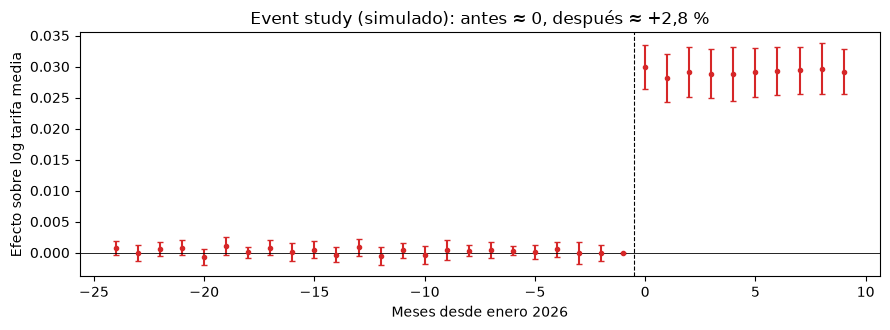

In [2]:
trat = set(verdad[verdad].index)
es, att, se = event_study(sim, trat, INICIO)
d = sim[sim.verdad_fraude_activo]
real = np.log(d.tarifa_media / d.verdad_tarifa_media_cf).mean()
print(f'Efecto estimado por DiD (pista acertada): {att:+.4f} log-puntos (≈ {np.expm1(att):+.2%}), error estándar {se:.4f}')
print(f'Efecto verdadero en la simulación:         {real:+.4f}')
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.errorbar(es.t, es.coef, yerr=1.96 * es.se, fmt='o', ms=3, capsize=2, color='tab:red')
ax.axhline(0, color='k', lw=.6); ax.axvline(-.5, ls='--', color='k', lw=.8)
ax.set_xlabel('Meses desde enero 2026'); ax.set_ylabel('Efecto sobre log tarifa media'); ax.set_title('Event study (simulado): antes ≈ 0, después ≈ +2,8 %')
plt.tight_layout(); plt.savefig('../outputs/figures/m02_event_study.png', dpi=150); plt.show()

**Lectura:** antes de enero los coeficientes están pegados a cero (tendencias paralelas: el supuesto se sostiene en esta simulación) y después saltan y se quedan arriba.

Ahora, la pista contaminada: misma cantidad de líneas inocentes mezcladas con las sospechadas.

In [3]:
rng = np.random.default_rng(0); inocentes = verdad[~verdad].index.to_numpy()
rows = []
for contam in (0, .25, .5, .75):
    n_mal = int(round(len(trat) * contam / (1 - contam))) if contam else 0
    lista = trat | set(rng.choice(inocentes, n_mal, replace=False))
    _, a, s = event_study(sim, lista, INICIO)
    rows.append({'% de la lista que es inocente': f'{contam:.0%}', 'efecto estimado': round(a, 4), 'error est.': round(s, 4)})
pd.DataFrame(rows)

,% de la lista que es inocente,efecto estimado,error est.
0,0%,0.0289,0.0019
1,25%,0.0215,0.0031
2,50%,0.0157,0.0028
3,75%,0.0079,0.0019


Una lista imprecisa **diluye** el efecto en proporción: si la mitad es inocente, el efecto estimado es la mitad. El DiD es tan bueno como la pista con la que se arma el grupo tratado. Y ojo: que acá recupere el efecto casi exacto se debe a que la simulación no tiene otros factores que confundan; con datos reales, los hay.

## Parte B · Control sintético, línea por línea
Para cada línea armamos su fantasma con líneas de su mismo grupo, ajustando sobre los 36 meses previos. Para no contaminar el contrafactual, **excluimos como donantes** a las líneas que el método 01 ya había marcado.

Para decidir cuándo una brecha es "grande" hay que saber cuánta brecha aparece por puro azar. Hacemos un **placebo en el tiempo**: fingimos que la fecha de inicio fue marzo de 2025 (cuando no pasó nada) y medimos las brechas resultantes.
El puntaje de cada línea es la brecha media posterior dividida por su error de ajuste previo (cuántos "errores típicos" se despega).

In [4]:
ex = set(m01[m01.mes_quiebre.notna()].linea_id)                  # donantes sospechosos según el método 01
placebo, _ = control_sintetico(wide, grupo, '2025-03-01', '2025-12-01')   # fecha falsa: no debería encontrar nada
sc, brechas = control_sintetico(wide, grupo, INICIO, excluir_donantes=ex)
sc['fraude'] = sc.linea_id.map(verdad)
umbral = placebo.puntaje.quantile(.99)
sc['marca'] = (sc.puntaje > umbral) & (sc.brecha_media > 0) & (sc.meses_post >= 3)
print(f'Líneas evaluables: {len(sc)} de {wide.shape[1]} (necesitan 36 meses de historia completa y donantes con datos)')
print(f'Umbral (percentil 99 del placebo): {umbral:.2f}')
print(f'AUC del puntaje: {roc_auc_score(sc.fraude, sc.puntaje):.3f}')
tp, fp, fn = (sc.marca & sc.fraude).sum(), (sc.marca & ~sc.fraude).sum(), (~sc.marca & sc.fraude).sum()
print(f'Marcadas: TP={tp} FP={fp} FN={fn} | precisión {tp/(tp+fp):.0%}, recall sobre evaluables {tp/(tp+fn):.0%}, recall sobre TODAS las líneas con fraude {tp/verdad.sum():.0%}')

Líneas evaluables: 278 de 390 (necesitan 36 meses de historia completa y donantes con datos)
Umbral (percentil 99 del placebo): 1.05
AUC del puntaje: 1.000
Marcadas: TP=19 FP=7 FN=0 | precisión 73%, recall sobre evaluables 100%, recall sobre TODAS las líneas con fraude 70%


**Dos decisiones que conviene declarar:** (1) probamos primero el percentil 95 del placebo, que dejaba demasiadas falsas alarmas (19 en una versión anterior de la simulación), y pasamos al 99; esa elección la hicimos *después* de ver resultados, así que es un ajuste que en la práctica habría que fijar de antemano. (2) Exigimos al menos 3 meses posteriores para marcar una línea: la falsa alarma más fuerte tenía un solo mes de datos.

Los gráficos clásicos del control sintético: la brecha entre cada línea y su fantasma. En gris, las líneas sin fraude (fluctúan alrededor de cero); en rojo, las que tienen fraude (despegan en enero).

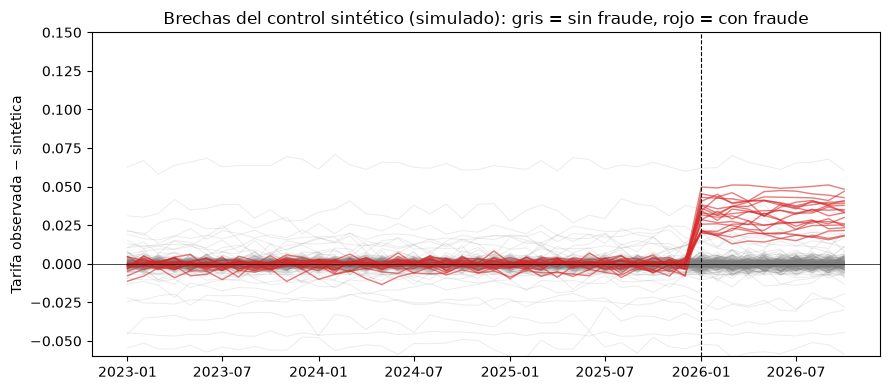

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for lid, g in brechas.items():
    if not verdad[lid]: ax.plot(g.index, g, color='tab:gray', alpha=.15, lw=.7)
for lid, g in brechas.items():
    if verdad[lid]: ax.plot(g.index, g, color='tab:red', alpha=.6, lw=1)
ax.axvline(pd.Timestamp(INICIO), ls='--', color='k', lw=.8); ax.axhline(0, color='k', lw=.5)
ax.set_ylim(-.06, .15); ax.set_ylabel('Tarifa observada − sintética'); ax.set_title('Brechas del control sintético (simulado): gris = sin fraude, rojo = con fraude')
plt.tight_layout(); plt.savefig('../outputs/figures/m02_brechas_sintetico.png', dpi=150); plt.show()

## Parte C · ¿Cuánto es el perjuicio?
Para cada línea marcada: sobrecobro = (tarifa media observada − sintética) × viajes, sumado desde enero. Como en la simulación conocemos el sobrecobro real, podemos ver cuán bien lo estima el método.
Unidades: "tarifa de sección 1 × viaje" (la tarifa real en pesos no está en la simulación).

In [6]:
est = sobrecobro_estimado(sim, brechas, list(sc[sc.marca].linea_id), INICIO).merge(verdad.rename('fraude'), left_on='linea_id', right_index=True)
d = sim[sim.verdad_fraude_activo]
real_total = (d.recaudacion - d.verdad_recaudacion_cf).sum()
tabla = pd.Series({
    'Sobrecobro REAL, todas las líneas con fraude': real_total,
    'Sobrecobro REAL, solo líneas con fraude marcadas': est[est.fraude].sobrecobro_real.sum(),
    'Sobrecobro ESTIMADO en esas mismas líneas': est[est.fraude].sobrecobro_est.sum(),
    'Sobrecobro estimado en falsas alarmas': est[~est.fraude].sobrecobro_est.sum(),
    'Sobrecobro ESTIMADO total (todas las marcadas)': est.sobrecobro_est.sum()})
print((tabla / 1e6).round(2).rename(lambda s: s + ' [millones]').to_string())
print(f"\nError de la estimación sobre las líneas bien marcadas: {est[est.fraude].sobrecobro_est.sum() / est[est.fraude].sobrecobro_real.sum() - 1:+.1%}")
print(f"Error del total estimado vs el sobrecobro real total: {est.sobrecobro_est.sum() / real_total - 1:+.1%}")

Sobrecobro REAL, todas las líneas con fraude [millones]        4.74
Sobrecobro REAL, solo líneas con fraude marcadas [millones]    2.94
Sobrecobro ESTIMADO en esas mismas líneas [millones]           2.89
Sobrecobro estimado en falsas alarmas [millones]               0.44
Sobrecobro ESTIMADO total (todas las marcadas) [millones]      3.33

Error de la estimación sobre las líneas bien marcadas: -1.6%
Error del total estimado vs el sobrecobro real total: -29.8%


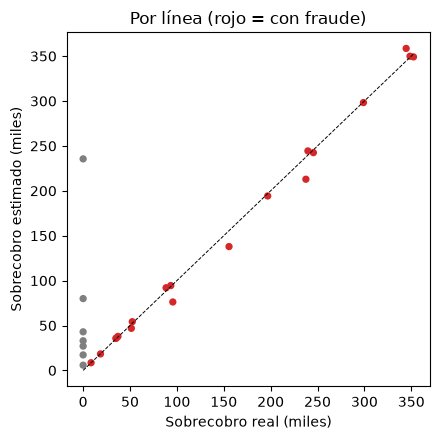

In [7]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
p = est.groupby(['linea_id', 'fraude'], as_index=False)[['sobrecobro_real', 'sobrecobro_est']].sum()
ax.scatter(p.sobrecobro_real / 1e3, p.sobrecobro_est / 1e3, c=p.fraude.map({True: 'tab:red', False: 'tab:gray'}), s=18)
m = p.sobrecobro_real.max() / 1e3; ax.plot([0, m], [0, m], 'k--', lw=.7)
ax.set_xlabel('Sobrecobro real (miles)'); ax.set_ylabel('Sobrecobro estimado (miles)'); ax.set_title('Por línea (rojo = con fraude)')
plt.tight_layout(); plt.savefig('../outputs/figures/m02_perjuicio_estimado_vs_real.png', dpi=150); plt.show()

### El efecto sobre el reparto de la bolsa
Si descontamos a cada empresa su sobrecobro estimado y repartimos de nuevo la bolsa fija, la diferencia con lo que cobraron es la **transferencia** hacia las empresas infladoras (y desde las demás).

In [8]:
te = transferencia_estimada(sub, est, INICIO, 100.0)
real_t = sub[(sub.mes >= INICIO) & sub.empresa_fraude].transferencia.sum()
est_t = te[te.empresa_fraude].transferencia_est.sum()
print(f'Transferencia real hacia empresas con fraude (2026, en % de una bolsa mensual): {real_t:.2f}')
print(f'Transferencia estimada para esas empresas:                                    {est_t:.2f}  ({est_t / real_t - 1:+.0%})')

Transferencia real hacia empresas con fraude (2026, en % de una bolsa mensual): 2.14
Transferencia estimada para esas empresas:                                    1.28  (-40%)


## Comparación con el método 01
Ambos detectan casi todo en este escenario. La diferencia es qué *entregan*: el 01 dice **cuándo** cambió la serie; el 02 dice **cuánto** se despegó y permite poner un número al perjuicio.

In [9]:
r1 = m01.set_index('linea_id').join(verdad.rename('fraude')); r1 = r1[r1.index.isin(sc.linea_id)]
print(f"AUC método 01 (salto en σ), mismas líneas: {roc_auc_score(r1.fraude, r1.salto_sigma):.3f}")
print(f"AUC método 02 (control sintético):          {roc_auc_score(sc.fraude, sc.puntaje):.3f}")
sc.to_parquet('../data/processed/res_m02_sintetico.parquet')

AUC método 01 (salto en σ), mismas líneas: 0.995
AUC método 02 (control sintético):          1.000


## Limitaciones
- **Cobertura:** el control sintético solo evalúa líneas con 36 meses de historia completa. Las líneas más nuevas quedan afuera y el perjuicio total se **subestima** por esa razón.
- **Simulación limpia:** sin otros shocks que afecten a unas líneas y no a otras, el DiD y el sintético funcionan mejor que en la vida real. Con datos reales, un cambio de recorrido o una obra se confunde con el efecto.
- **Contaminación de donantes:** si muchas líneas del grupo inflan a la vez, el fantasma también sube y el efecto se subestima (por eso excluimos las marcadas por el método 01).
- **Dependencia entre métodos:** este análisis usa la salida del método 01 para depurar donantes; en la Fase 4 hay que evaluar con cuidado esa dependencia.
- **Siguiente (método 03):** la coherencia geográfica, que no mira la serie en el tiempo sino si lo cobrado es *posible* dado el largo del recorrido.